<a href="https://colab.research.google.com/github/yoonie03/data-science-toolkit/blob/library%2Fnumpy/Tutorial05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

------------Tutorial 05-------------------

Instruction

1.Use the salary data

2.Handles Incomplete, noise and inconsistent values:
```plain text
	Data Preprocessing-Cleaning:
          1.Incomplete (Missing Values)
          2.Noise (Either errors)
          3.Inconsistent Values
```

In [1]:
# Standard libraries
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn libraries
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest, f_classif

In [3]:
import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/Dataset/DiabetesData.csv"
df = pd.read_csv(path)

In [4]:
df.head()

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
0,148.0,72,35,0.0,33.6,0.627,50.0,1
1,85.0,66,29,0.0,26.6,0.351,31.0,0
2,183.0,64,0,0.0,23.3,0.672,32.0,1
3,89.0,66,23,94.0,28.1,0.167,21.0,0
4,137.0,40,35,168.0,43.1,2.288,33.0,1


In [6]:
#use df.info to identify which columns has a lot of missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Sugar     765 non-null    float64
 1   BP        768 non-null    int64  
 2   Skin      768 non-null    int64  
 3   Insulin   767 non-null    float64
 4   BMI       766 non-null    float64
 5   Pedigree  766 non-null    float64
 6   Age       767 non-null    float64
 7   Label     768 non-null    int64  
dtypes: float64(5), int64(3)
memory usage: 48.1 KB


missing value check

In [9]:
# Write a code to return the number of rows
# Guide: isna().sum()
df.isnull().sum()
print('--Columns and the number of missing values--')

#Your code here.
for column_name in df.columns:
  n_missing = df[column_name].isnull().sum()
  print(f'{column_name} : {n_missing}')

--Columns and the number of missing values--
Sugar : 3
BP : 0
Skin : 0
Insulin : 1
BMI : 2
Pedigree : 2
Age : 1
Label : 0


# 1.2 Dropping missing values

- We can drop missing values here using `dropna()` function.
- If we do `dropna()` without specifying any parameter, it will drop rows that has even 1 missing values
- If we do `dropna(thresh=2)` it will drop rows that has more than 2 missing values
- If we do `dropna(how=all)` it will drop only rows where all values are missing
- [Re_pandas](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html)

In [10]:
df_drop = df.dropna()
df_drop.head()

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
0,148.0,72,35,0.0,33.6,0.627,50.0,1
1,85.0,66,29,0.0,26.6,0.351,31.0,0
2,183.0,64,0,0.0,23.3,0.672,32.0,1
3,89.0,66,23,94.0,28.1,0.167,21.0,0
4,137.0,40,35,168.0,43.1,2.288,33.0,1


In [11]:
# Compare the number of rows before and after dropna()
print('before dropna()')
print(df.shape)

print()

print('after dropna()')
print(df_drop.shape)

before dropna()
(768, 8)

after dropna()
(759, 8)


In [12]:
df_drop.isnull().sum()

,0
Sugar,0
BP,0
Skin,0
Insulin,0
BMI,0
Pedigree,0
Age,0
Label,0


# 1.4 Impute missing values with most frequent

- A simple method where we don't analyse per column.
- We can impute missing values for all related columns using most frequent.
- Imputed values can be the mean, median. This is changed in the 'strategy' parameter.
- There are other simple methods for imputing missing values. Eg `fill.na()`

[sklearn.SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html$0)


```
class sklearn.impute.SimpleImputer(*, missing_values=nan, strategy='mean', fill_value=None, copy=True, add_indicator=False, keep_empty_features=False)
```



In [13]:
#method 2

from sklearn.impute import SimpleImputer
si = SimpleImputer(strategy = 'median')
df_si = si.fit_transform(df)

df_si = pd.DataFrame(df_si, columns=df.columns)
df_si.isnull().sum()

,0
Sugar,0
BP,0
Skin,0
Insulin,0
BMI,0
Pedigree,0
Age,0
Label,0


In [14]:
df_si

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,1.0
1,85.0,66.0,29.0,0.0,26.6,0.351,31.0,0.0
2,183.0,64.0,0.0,0.0,23.3,0.672,32.0,1.0
3,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0
4,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0
...,...,...,...,...,...,...,...,...
763,101.0,76.0,48.0,180.0,32.9,0.171,63.0,0.0
764,122.0,70.0,27.0,0.0,36.8,0.340,27.0,0.0
765,121.0,72.0,23.0,112.0,26.2,0.245,30.0,0.0
766,126.0,60.0,0.0,0.0,30.1,0.349,47.0,1.0


In [15]:
df_si.shape

(768, 8)

# 2.1 Noisy data

- Noise can be random errors and/or outliers

## 2.1 Remove outliers

- Use boxplot or histograms to find outliers `(df.boxplot() or df.hist())`
- Outliers are values that are waaay higher or lower than most of the data. Usually there are not many data points like this. So we can
consider this as noise

<Axes: >

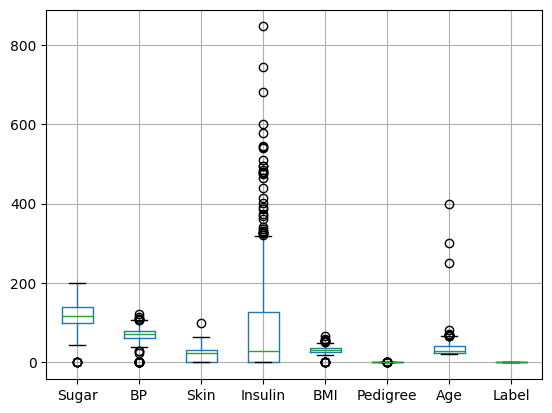

In [16]:
df.boxplot()

There are 3 outliers in the 'Age' column. Realistically, age cannot be over 200

array([[<Axes: title={'center': 'Sugar'}>,
        <Axes: title={'center': 'BP'}>, <Axes: title={'center': 'Skin'}>],
       [<Axes: title={'center': 'Insulin'}>,
        <Axes: title={'center': 'BMI'}>,
        <Axes: title={'center': 'Pedigree'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Label'}>, <Axes: >]], dtype=object)

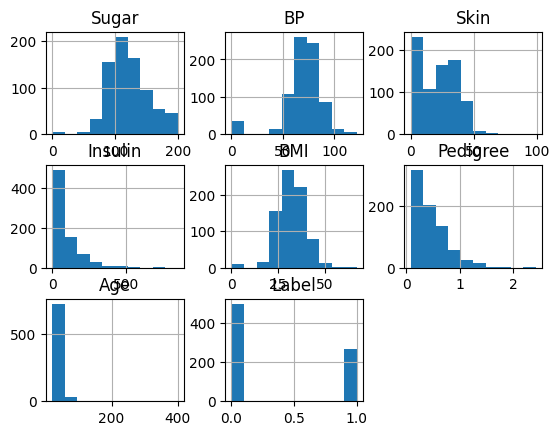

In [18]:
df.hist()

- Can remove using stats [Ref_stackoverflow](https://stackoverflow.com/questions/23199796/detect-and-exclude-outliers-in-a-pandas-dataframe)
- Can also remove manually

[`scipy.stats`](https://docs.scipy.org/doc/scipy-1.18.0/reference/stats.html$0)

- For each column, it first computes the Z-score of each value in the column, relative to the column mean and standard deviation.
- It then takes the absolute Z-score because the direction does not matter, only if it is below the threshold.
- `( < 3).all(axis=1)` checks if, for each row, all column values are within 3 standard deviations from the mean
- Finally, the result of this condition is used to index the dataframe.

- Filter other columns based on a single column

  - The same as above, but specify a column for the zscore, `df[0]` for example, and remove `.all(axis=1).`

```python
df[np.abs(stats.zscore(df[0])) < 3]
```

In [31]:
from scipy import stats
# Your code here to remove manually.
age_z = stats.zscore(df['Age'], nan_policy='omit')
df_stats = df[np.abs(age_z) < 3]
df_stats

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
0,148.0,72,35,0.0,33.6,0.627,50.0,1
1,85.0,66,29,0.0,26.6,0.351,31.0,0
2,183.0,64,0,0.0,23.3,0.672,32.0,1
3,89.0,66,23,94.0,28.1,0.167,21.0,0
4,137.0,40,35,168.0,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...
763,101.0,76,48,180.0,32.9,0.171,63.0,0
764,122.0,70,27,0.0,36.8,0.340,27.0,0
765,121.0,72,23,112.0,26.2,0.245,30.0,0
766,126.0,60,0,0.0,30.1,0.349,47.0,1


In [32]:
print(df.shape)
print(df_stats.shape)

(768, 8)
(764, 8)


## 2.2 Remove non sensible values

In [17]:
# Use df.describe()
df.describe()

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
count,765.000000,768.000000,768.000000,767.000000,766.000000,766.000000,767.000000,768.000000
mean,120.882353,69.105469,20.536458,79.788787,31.979765,0.472110,34.344198,0.348958
std,31.979980,19.355807,15.952218,115.318821,7.889584,0.331669,21.609915,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,99.000000,62.000000,0.000000,0.000000,27.300000,0.243250,24.000000,0.000000
50%,117.000000,72.000000,23.000000,29.000000,32.000000,0.372500,29.000000,0.000000
75%,140.000000,80.000000,32.000000,127.500000,36.575000,0.626750,41.000000,1.000000
max,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,400.000000,1.000000


In [28]:
#Guide : df[df['col name'] > threshold ] to select sensible values
# Select elderly data (Age > 70) for outlier or threshold analysis
df_thr = df[df['Age'] > 70]
df_thr

,Sugar,BP,Skin,Insulin,BMI,Pedigree,Age,Label
10,110.0,92,0,0.0,37.6,0.191,250.0,0
35,103.0,60,33,192.0,24.0,0.966,300.0,0
72,126.0,90,0,0.0,43.4,0.583,400.0,1
453,119.0,0,0,0.0,19.6,0.832,72.0,0
459,134.0,74,33,60.0,25.9,0.460,81.0,0


# Bonus : Feature Exploration: Correlation Analysis


[`seaborn.heatmap`](https://seaborn.pydata.org/generated/seaborn.heatmap.html$0)

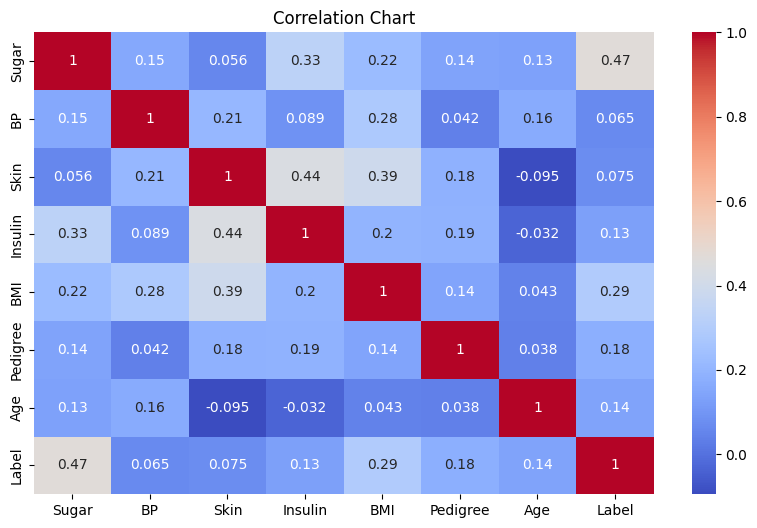

In [ ]:
corr = df.corr()
plt.figure(figsize = (10, 6))
sns.heatmap(corr, annot=True, cmap = 'coolwarm')
plt.title("Correlation Chart")
plt.show()